# Weeks 3–4 · Method B – Character reading
Run on Colab with a GPU (Runtime → Change runtime type → T4).
Training outputs are saved directly to Google Drive so nothing is lost if the session drops.

## 0. Setup: mount Drive, clone the repo, install packages

In [1]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive/DATH_bien_so'
BRANCH = 'main'

!git clone -b $BRANCH https://github.com/anhpham103/DATH_bien_so.git /content/repo || git -C /content/repo pull
%cd /content/repo
!pip -q install ultralytics onnx onnxslim onnxruntime

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
fatal: destination path '/content/repo' already exists and is not an empty directory.
Already up to date.
/content/repo


## 1. Copy the character dataset from Drive (week 2 output)

In [2]:
!mkdir -p datasets
!unzip -q -o $DRIVE/datasets/chars_clean.zip -d datasets/
!cp $DRIVE/datasets/plate_strings.csv datasets/
!ls datasets/chars/images/
!python -m pytest tests/ -q

train  val
..........                                                               [100%]
10 passed in 0.18s


In [9]:
!python scripts/make_plate_strings.py
!cp datasets/plate_strings.csv $DRIVE/datasets/
!cp results/plate_strings_review.csv $DRIVE/datasets/
!head -5 datasets/plate_strings.csv

/content/repo/scripts/make_plate_strings.py:8: UserWarning: src/rectify.py not found: using the Part 1 guide fallback.
  from _deps import clean, postprocess, split_raw
/content/repo/scripts/make_plate_strings.py:8: UserWarning: src/postprocess.py not found: using the Part 1 guide fallback.
  from _deps import clean, postprocess, split_raw
3822 plate strings -> /content/repo/datasets/plate_strings.csv (972 one-line, 2850 two-line)
Plate type from crops_index.csv: 0; from aspect ratio: 3822
1188 entries to check by hand -> /content/repo/results/plate_strings_review.csv
   0.jpg train 0123456789ABC|SDTEUFGVHXYKZLMNP fails format or province code
   10PlateBaza299.jpg train ZG|8894AB fails format or province code
   12xemay1338.jpg train 606|1172 postprocess would change it to 60G1172
   1PlateBaza487.jpg train VU279AE fails format or province code
   1PlateBaza493.jpg train ZG567EF fails format or province code
   1PlateBaza494.jpg train K531CC fails format or province code
   1PlateBaza

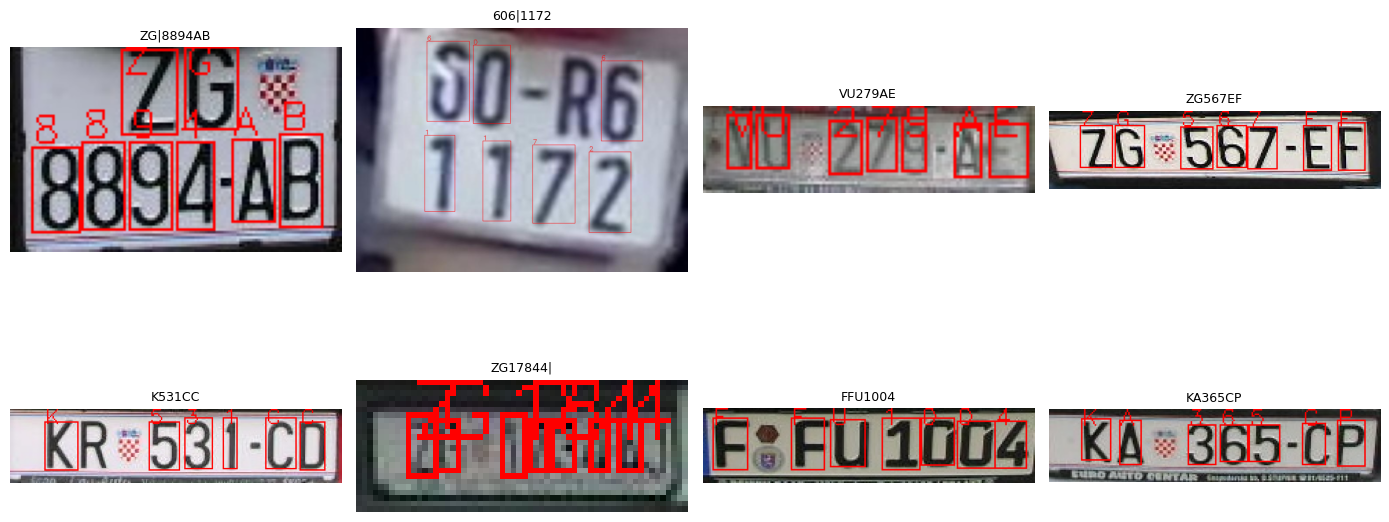

ndata           0:521 1:673 2:639 3:501 4:305 5:388 6:349 7:364 8:343 9:619 A:57 B:49 C:8 D:138 E:86 F:36 G:14 H:17 K:38 L:21 M:154 N:24 P:6 S:5 T:6 U:14 V:21 X:34 Y:25 Z:7
iwt             0:327 1:408 2:338 3:341 4:375 5:351 6:349 7:353 8:409 9:354 A:44 B:528 C:30 D:8 E:16 F:6 G:2 H:5 K:2 L:11 M:20 N:5 P:6 S:8 T:22 U:0 V:4 X:6 Y:0 Z:56
3xemay          0:247 1:476 2:287 3:233 4:249 5:505 6:255 7:255 8:193 9:410 A:3 B:30 C:37 D:17 E:13 F:30 G:5 H:30 K:19 L:38 M:8 N:15 P:32 S:34 T:25 U:16 V:15 X:15 Y:8 Z:11
2xemay          0:181 1:418 2:225 3:197 4:207 5:398 6:189 7:201 8:173 9:344 A:3 B:27 C:27 D:10 E:17 F:28 G:3 H:18 K:17 L:20 M:12 N:14 P:33 S:33 T:16 U:14 V:12 X:11 Y:6 Z:3
3CarLongPlate   0:165 1:349 2:154 3:86 4:109 5:313 6:130 7:104 8:84 9:106 A:71 B:2 C:1 D:5 E:2 F:101 G:38 H:0 K:0 L:5 M:1 N:2 P:0 S:0 T:0 U:0 V:2 X:0 Y:2 Z:2
5xemay          0:115 1:235 2:151 3:119 4:117 5:233 6:138 7:125 8:100 9:218 A:3 B:15 C:12 D:4 E:6 F:25 G:5 H:14 K:8 L:21 M:10 N:1 P:20 S:16 T:7 U:9 V:8 X:9 Y:5 

In [4]:
import csv, re, cv2, matplotlib.pyplot as plt
from collections import Counter, defaultdict
CHARS = list("0123456789ABCDEFGHKLMNPSTUVXYZ")

rows = list(csv.DictReader(open('results/plate_strings_review.csv')))
plt.figure(figsize=(14, 7))
for i, r in enumerate(rows[1:9]):
    img = cv2.imread(f"datasets/chars/images/{r['split']}/{r['crop_path']}")
    h, w = img.shape[:2]
    stem = r['crop_path'].rsplit('.', 1)[0]
    for line in open(f"datasets/chars/labels/{r['split']}/{stem}.txt"):
        c, xc, yc, bw, bh = line.split(); c = int(c)
        x1, y1 = int((float(xc) - float(bw)/2) * w), int((float(yc) - float(bh)/2) * h)
        x2, y2 = int((float(xc) + float(bw)/2) * w), int((float(yc) + float(bh)/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 1)
        cv2.putText(img, CHARS[c], (x1, max(y1 - 2, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
    plt.subplot(2, 4, i + 1); plt.imshow(img[:, :, ::-1]); plt.title(r['text'], fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

by_src = defaultdict(Counter)
import glob, os
for f in glob.glob('datasets/chars/labels/*/*.txt'):
    src = re.sub(r'\d+$', '', os.path.basename(f)[:-4]) or 'other'
    for line in open(f):
        by_src[src][CHARS[int(line.split()[0])]] += 1
for src, cnt in sorted(by_src.items(), key=lambda kv: -sum(kv[1].values()))[:6]:
    print(f"{src:<15}", ' '.join(f"{ch}:{cnt[ch]}" for ch in CHARS))


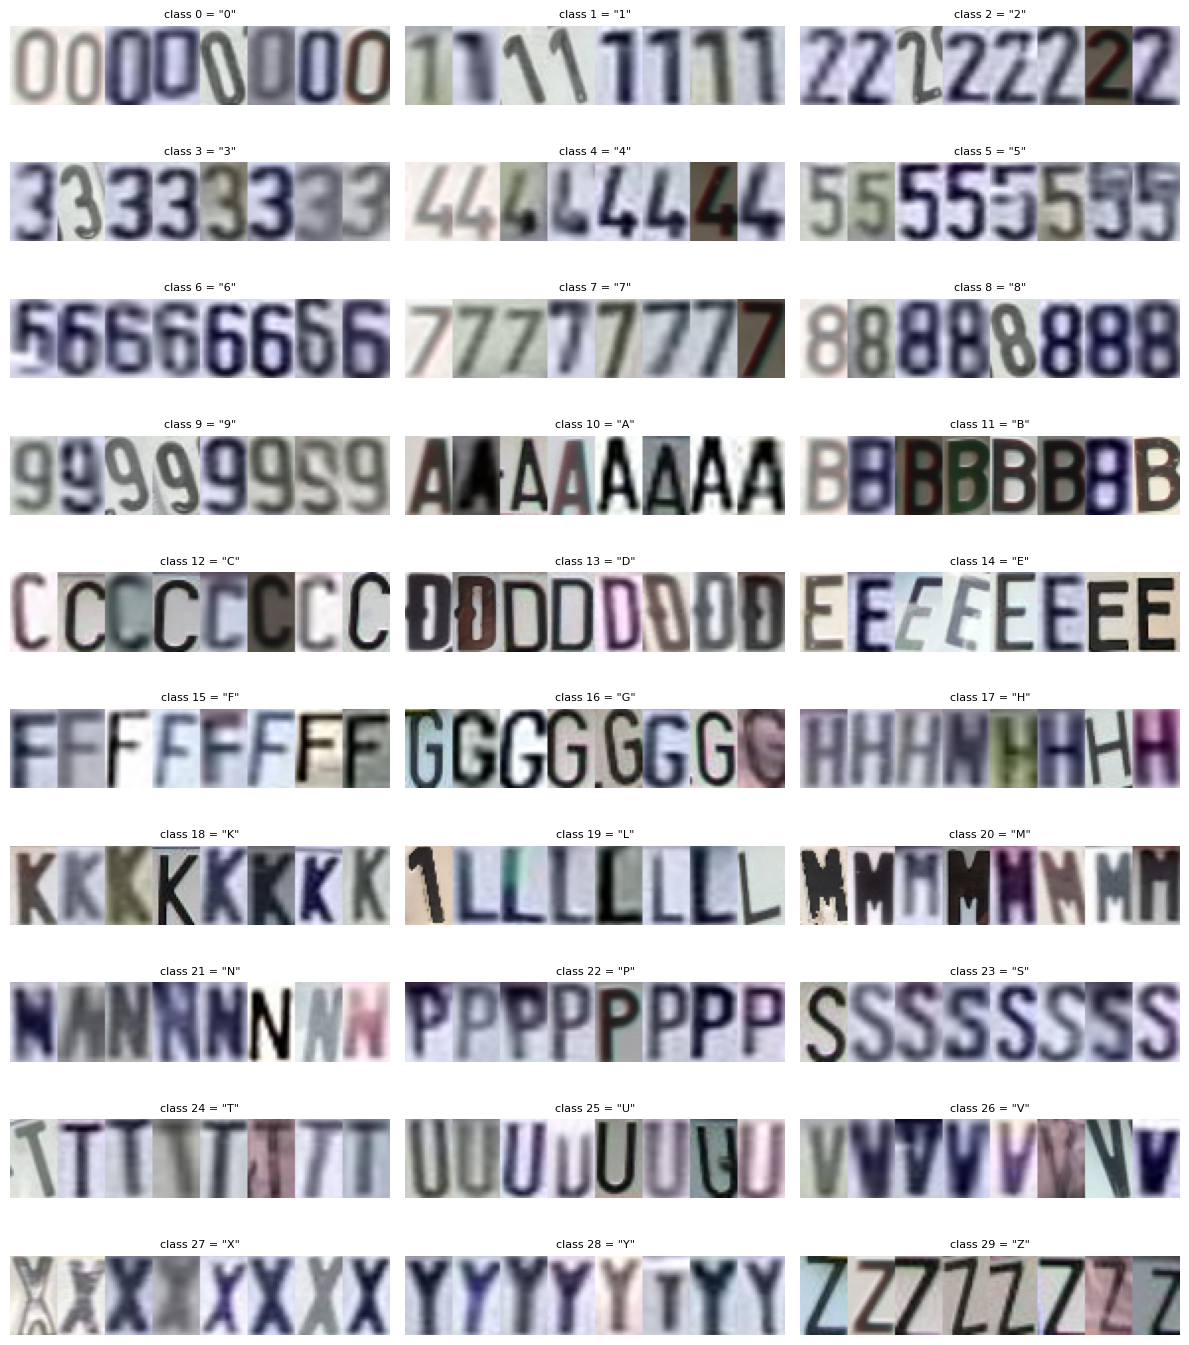

In [5]:
import glob, os, cv2, random, matplotlib.pyplot as plt
CHARS = list("0123456789ABCDEFGHKLMNPSTUVXYZ")
random.seed(0)
samples = {c: [] for c in range(30)}
files = glob.glob('datasets/chars/labels/train/*.txt'); random.shuffle(files)
for f in files:
    stem = os.path.basename(f)[:-4]
    img = None
    for line in open(f):
        c, xc, yc, bw, bh = line.split(); c = int(c)
        if len(samples[c]) >= 8: continue
        if img is None:
            img = cv2.imread(f'datasets/chars/images/train/{stem}.jpg')
            if img is None: break
            h, w = img.shape[:2]
        x1, y1 = max(int((float(xc)-float(bw)/2)*w), 0), max(int((float(yc)-float(bh)/2)*h), 0)
        x2, y2 = int((float(xc)+float(bw)/2)*w), int((float(yc)+float(bh)/2)*h)
        samples[c].append(cv2.resize(img[y1:y2, x1:x2], (24, 40)))
    if all(len(v) >= 8 for v in samples.values()): break
plt.figure(figsize=(12, 14))
for c in range(30):
    if samples[c]:
        plt.subplot(10, 3, c + 1); plt.imshow(cv2.hconcat(samples[c])[:, :, ::-1])
    plt.title(f'class {c} = "{CHARS[c]}"', fontsize=8); plt.axis('off')
plt.tight_layout(); plt.show()

In [6]:
import csv, re
from collections import Counter
review = list(csv.DictReader(open('results/plate_strings_review.csv')))
allrows = list(csv.DictReader(open('datasets/plate_strings.csv')))
src = lambda name: re.sub(r'^\d+|\d+\.\w+$', '', name) or name
print("Tổng ảnh theo nguồn:", Counter(src(r['crop_path']) for r in allrows))
print("Cần xem lại theo nguồn:", Counter(src(r['crop_path']) for r in review))
print("Cần xem lại theo lý do:", Counter(r['reason'].split(' to ')[0] for r in review))
print("Cần xem lại theo tập:", Counter(r['split'] for r in review))

Tổng ảnh theo nguồn: Counter({'xemay': 1772, 'iwt': 643, 'ndata': 634, 'CarLongPlate': 511, 'PlateBaza': 261, '.jpg': 1})
Cần xem lại theo nguồn: Counter({'iwt': 643, 'PlateBaza': 261, 'ndata': 213, 'xemay': 54, 'CarLongPlate': 16, '.jpg': 1})
Cần xem lại theo lý do: Counter({'fails format or province code': 890, 'postprocess would change it': 285, 'empty label file': 11, 'one line is empty': 2})
Cần xem lại theo tập: Counter({'train': 956, 'val': 232})


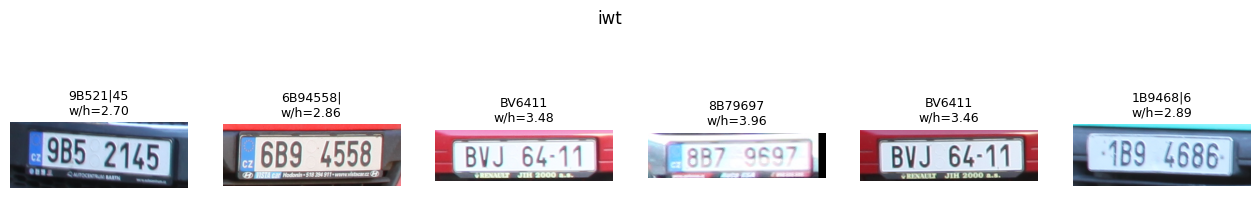

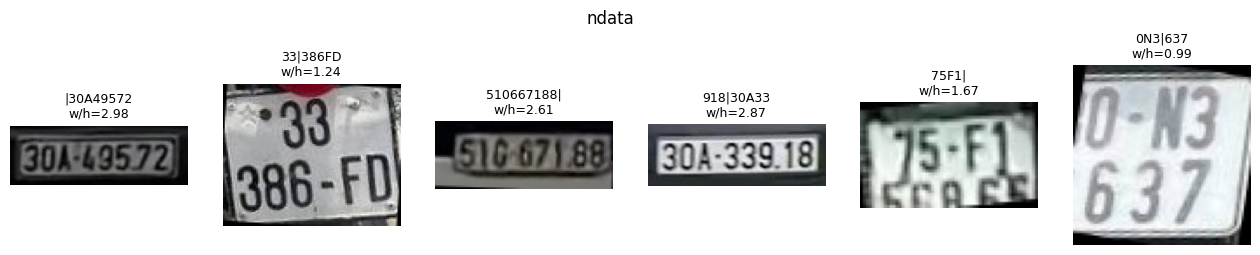

In [7]:
import cv2, matplotlib.pyplot as plt
for name in ('iwt', 'ndata'):
    rows = [r for r in review if src(r['crop_path']) == name][:6]
    plt.figure(figsize=(16, 3))
    for i, r in enumerate(rows):
        img = cv2.imread(f"datasets/chars/images/{r['split']}/{r['crop_path']}")
        h, w = img.shape[:2]
        plt.subplot(1, 6, i + 1); plt.imshow(img[:, :, ::-1]); plt.axis('off')
        plt.title(f"{r['text']}\nw/h={w/h:.2f}", fontsize=9)
    plt.suptitle(name); plt.show()

In [8]:
!wget -q -O scripts/make_plate_strings.py https://raw.githubusercontent.com/anhpham103/DATH_bien_so/main/scripts/make_plate_strings.py


In [10]:
import csv, re, os, shutil
from collections import Counter
FOREIGN = {'iwt', 'PlateBaza'}
src = lambda name: re.sub(r'^\d+|\d+\.\w+$', '', name) or name
review = list(csv.DictReader(open('results/plate_strings_review.csv')))

moved = Counter()
for r in review:
    s = src(r['crop_path'])
    if r['split'] == 'train' and s in FOREIGN and r['crop_path'] != '0.jpg':
        continue
    stem = r['crop_path'].rsplit('.', 1)[0]
    for sub, name in (('images', r['crop_path']), ('labels', stem + '.txt')):
        p = f"datasets/chars/{sub}/{r['split']}/{name}"
        if os.path.exists(p):
            dst = f"datasets/chars_excluded/{sub}/{r['split']}/{name}"
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.move(p, dst)
    moved[(r['split'], s)] += 1
print("Đã loại:", dict(moved))

!python scripts/make_plate_strings.py 2>/dev/null | head -3
!for s in train val; do echo $s $(ls datasets/chars/images/$s | wc -l); done
!cp datasets/plate_strings.csv $DRIVE/datasets/
!cd datasets && zip -qr $DRIVE/datasets/chars_clean.zip chars chars_excluded

Đã loại: {('train', '.jpg'): 1, ('train', 'xemay'): 44, ('train', 'CarLongPlate'): 10, ('train', 'ndata'): 170, ('val', 'PlateBaza'): 54, ('val', 'xemay'): 10, ('val', 'CarLongPlate'): 6, ('val', 'iwt'): 119, ('val', 'ndata'): 43}
3376 plate strings -> /content/repo/datasets/plate_strings.csv (863 one-line, 2513 two-line)
Plate type from crops_index.csv: 0; from aspect ratio: 3376
731 entries to check by hand -> /content/repo/results/plate_strings_review.csv
ls: cannot access 'datasets/chars/images/ndata': No such file or directory
ndata 0
ls: cannot access 'datasets/chars/images/ndata': No such file or directory
ndata 0


In [11]:
import os, shutil
n = 0
for root, _, files in os.walk('datasets/chars_excluded'):
    for f in files:
        src_p = os.path.join(root, f)
        dst_p = src_p.replace('datasets/chars_excluded', 'datasets/chars', 1)
        os.makedirs(os.path.dirname(dst_p), exist_ok=True)
        shutil.move(src_p, dst_p); n += 1
shutil.rmtree('datasets/chars_excluded', ignore_errors=True)
print("Đã khôi phục", n, "file")

Đã khôi phục 914 file


In [12]:
%%writefile scripts/make_plate_strings.py
import argparse
import csv
from pathlib import Path

import cv2

from _common import CHARS, IMG_EXTS, ROOT, SPLITS, git_commit, is_two_lines
from _deps import clean, postprocess, split_raw
from read_chars import sort_chars

NAME_COLS = ("crop_path", "crop", "crop_name", "image", "img", "file", "filename", "path")
TYPE_COLS = ("plate_type", "type", "cls", "class", "class_name", "loai_bien", "two_lines")


def load_plate_types(path):
    if not path or not Path(path).exists():
        return {}
    with open(path, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        cols = {c.lower().strip(): c for c in reader.fieldnames}
        nc = next((cols[c] for c in NAME_COLS if c in cols), None)
        tc = next((cols[c] for c in TYPE_COLS if c in cols), None)
        if nc is None or tc is None:
            print(f"[note] {path}: name/type columns not recognized, using aspect ratio instead")
            return {}
        return {Path(r[nc]).stem: is_two_lines(r[tc]) for r in reader}


def infer_two_lines(boxes, min_gap_rel=0.5):
    if len(boxes) < 2:
        return None
    ys = sorted(b[1] for b in boxes)
    med_h = sorted(b[2] for b in boxes)[len(boxes) // 2]
    gap = max(ys[k + 1] - ys[k] for k in range(len(ys) - 1))
    return gap > min_gap_rel * med_h


def read_boxes(label_path, w, h):
    boxes = []
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue
        c, xc, yc, _, bh = int(parts[0]), *map(float, parts[1:])
        boxes.append((xc * w, yc * h, bh * h, CHARS[c]))
    return boxes


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--src", default=str(ROOT / "datasets" / "chars"))
    ap.add_argument("--crops-index", default=str(ROOT / "datasets" / "crops_index.csv"))
    ap.add_argument("--out", default=str(ROOT / "datasets" / "plate_strings.csv"))
    ap.add_argument("--review", default=str(ROOT / "results" / "plate_strings_review.csv"))
    ap.add_argument("--ratio", type=float, default=3.0,
                    help="fallback only: width/height below this is treated as a 2-line plate")
    args = ap.parse_args()

    types = load_plate_types(args.crops_index)
    src = Path(args.src)
    rows, review = [], []
    n_type_from_index = n_type_from_boxes = 0

    for split in SPLITS:
        img_dir = src / "images" / split
        if not img_dir.is_dir():
            continue
        for img_path in sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXTS):
            lbl = src / "labels" / split / f"{img_path.stem}.txt"
            if not lbl.exists():
                continue
            img = cv2.imread(str(img_path))
            if img is None:
                review.append((img_path.name, split, "", "unreadable image"))
                continue
            h, w = img.shape[:2]
            boxes = read_boxes(lbl, w, h)
            if not boxes:
                review.append((img_path.name, split, "", "empty label file"))
                continue
            from_boxes = infer_two_lines(boxes)
            if img_path.stem in types:
                two = types[img_path.stem]
                n_type_from_index += 1
            elif from_boxes is not None:
                two = from_boxes
                n_type_from_boxes += 1
            else:
                two = w / h < args.ratio
            text = sort_chars(boxes, two, img_h=h, min_rel_h=0.0)
            plate, ok = postprocess(*split_raw(text))
            rows.append((img_path.name, split, text, int(two), int(ok)))
            if not ok:
                review.append((img_path.name, split, text, "fails format or province code"))
            elif plate != clean(text):
                review.append((img_path.name, split, text, f"postprocess would change it to {plate}"))
            elif two and (text.startswith("|") or text.endswith("|")):
                review.append((img_path.name, split, text, "one line is empty"))

    Path(args.out).parent.mkdir(parents=True, exist_ok=True)
    with open(args.out, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["crop_path", "split", "text", "two_lines", "valid"])
        w.writerows(rows)

    Path(args.review).parent.mkdir(parents=True, exist_ok=True)
    with open(args.review, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["crop_path", "split", "text", "reason", "commit"])
        commit = git_commit()
        w.writerows((*r, commit) for r in review)

    n2 = sum(r[3] for r in rows)
    print(f"{len(rows)} plate strings -> {args.out} ({len(rows) - n2} one-line, {n2} two-line)")
    print(f"Line count from crops_index.csv: {n_type_from_index}; "
          f"from label boxes: {n_type_from_boxes}; "
          f"from aspect ratio: {len(rows) - n_type_from_index - n_type_from_boxes}")
    print(f"{len(review)} entries to check by hand -> {args.review}")
    for r in review[:10]:
        print("  ", *r)


if __name__ == "__main__":
    main()

Overwriting scripts/make_plate_strings.py


In [13]:
import csv, re, os, shutil, subprocess
from collections import Counter

print(subprocess.run(['python', 'scripts/make_plate_strings.py'], capture_output=True, text=True).stdout.split('\n   ')[0])

FOREIGN = {'iwt', 'PlateBaza'}
src_of = lambda name: re.sub(r'^\d+|\d+\.\w+$', '', name) or name
review = list(csv.DictReader(open('results/plate_strings_review.csv')))
print("Cần xem lại theo nguồn:", Counter((r['split'], src_of(r['crop_path'])) for r in review))

moved = Counter()
for r in review:
    s = src_of(r['crop_path'])
    if r['split'] == 'train' and s in FOREIGN and r['crop_path'] != '0.jpg':
        continue
    stem = r['crop_path'].rsplit('.', 1)[0]
    for sub, name in (('images', r['crop_path']), ('labels', stem + '.txt')):
        p = f"datasets/chars/{sub}/{r['split']}/{name}"
        if os.path.exists(p):
            dst = f"datasets/chars_excluded/{sub}/{r['split']}/{name}"
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.move(p, dst)
    moved[(r['split'], s)] += 1
print("Đã loại:", dict(moved))

subprocess.run(['python', 'scripts/make_plate_strings.py'], capture_output=True)
for split in ('train', 'val'):
    print(split, "còn", len(os.listdir(f'datasets/chars/images/{split}')), "ảnh")

3822 plate strings -> /content/repo/datasets/plate_strings.csv (1460 one-line, 2362 two-line)
Line count from crops_index.csv: 0; from label boxes: 3814; from aspect ratio: 8
1176 entries to check by hand -> /content/repo/results/plate_strings_review.csv
Cần xem lại theo nguồn: Counter({('train', 'iwt'): 524, ('train', 'PlateBaza'): 207, ('train', 'ndata'): 160, ('val', 'iwt'): 119, ('val', 'PlateBaza'): 54, ('train', 'xemay'): 44, ('val', 'ndata'): 41, ('train', 'CarLongPlate'): 10, ('val', 'xemay'): 10, ('val', 'CarLongPlate'): 6, ('train', '.jpg'): 1})
Đã loại: {('train', '.jpg'): 1, ('train', 'xemay'): 44, ('train', 'CarLongPlate'): 10, ('train', 'ndata'): 160, ('val', 'PlateBaza'): 54, ('val', 'xemay'): 10, ('val', 'CarLongPlate'): 6, ('val', 'iwt'): 119, ('val', 'ndata'): 41}
train còn 2851 ảnh
val còn 537 ảnh


In [14]:
!cp datasets/plate_strings.csv $DRIVE/datasets/
!rm -f $DRIVE/datasets/chars_clean.zip
!cd datasets && zip -qr $DRIVE/datasets/chars_clean.zip chars chars_excluded

## Week 3


In [ ]:
!python scripts/enhance_chars_dataset.py

### 3. Train YOLO26n, 30 classes, imgsz 320, fliplr=0 (about 2–4 hours on a T4)

In [ ]:
!python scripts/train_chars.py --project $DRIVE/runs/detect --device 0

In [ ]:
!python scripts/train_chars.py --project $DRIVE/runs/detect --resume

### 4. Try read_chars on a few validation images

In [ ]:
import sys, cv2, glob
sys.path[:0] = ['src', 'scripts']
from compare_ab import load_strings
from read_chars import read_chars, set_model
set_model('models/char_yolo26n.pt')
gts = load_strings('datasets/plate_strings.csv')
for p in sorted(glob.glob('datasets/chars_enh/images/val/*'))[:10]:
    stem = p.rsplit('/',1)[1].rsplit('.',1)[0]
    gt = gts.get(stem, '?')
    print(f"{stem:<30} read={read_chars(cv2.imread(p), '|' in gt):<12} gt={gt}")

## Week 4


In [ ]:
!pip -q install paddlepaddle paddleocr
!python scripts/compare_ab.py --split val

###  Export ONNX  

In [ ]:
!python scripts/export_chars_onnx.py
!python scripts/compare_ab.py --split val --engines B --model models/char_yolo26n.onnx --tag onnx

### Prepare 32x160 line images for method C

In [ ]:
!python scripts/prepare_lines_c.py
import cv2, glob, matplotlib.pyplot as plt
fs = sorted(glob.glob('datasets/lines/val/*_l1.png'))[:4] + sorted(glob.glob('datasets/lines/val/*_l0.png'))[:4]
plt.figure(figsize=(8, 4))
for i, f in enumerate(fs):
    plt.subplot(4, 2, i + 1); plt.imshow(cv2.imread(f)[:, :, ::-1]); plt.title(f.rsplit('/',1)[1], fontsize=7); plt.axis('off')
plt.tight_layout()

### 8. Save models, results and line images to Drive

In [ ]:
!mkdir -p $DRIVE/models $DRIVE/results $DRIVE/datasets
!cp models/char_yolo26n.* $DRIVE/models/
!cp results/*.csv $DRIVE/results/
!rsync -a datasets/lines/ $DRIVE/datasets/lines/